# 可选实验：使用 Scikit-Learn 实现线性回归

有一个开源、可商用的机器学习工具包叫做 [scikit-learn](https://scikit-learn.org/stable/index.html)。这个工具包包含你在本课程中会用到的许多算法的实现。

## 学习目标
在本实验中，你将：
- 利用 scikit-learn 使用梯度下降实现线性回归

## 工具
你将使用来自 scikit-learn 的函数，以及 matplotlib 和 NumPy。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
from lab_utils_multi import  load_house_data
from lab_utils_common import dlc
np.set_printoptions(precision=2)
plt.style.use('./deeplearning.mplstyle')

# 梯度下降
Scikit-learn 有一个梯度下降回归模型 [sklearn.linear_model.SGDRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html#examples-using-sklearn-linear-model-sgdregressor)。与你之前实现的梯度下降一样，这个模型在输入经过归一化时表现最佳。[sklearn.preprocessing.StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler) 会像之前的实验那样执行 z-score 归一化。在这里它被称为"标准分数"（standard score）。

### 加载数据集

In [2]:
X_train, y_train = load_house_data()
X_features = ['size(sqft)','bedrooms','floors','age']

### 缩放/归一化训练数据

In [3]:
scaler = StandardScaler()
X_norm = scaler.fit_transform(X_train)
print(f"Peak to Peak range by column in Raw        X:{np.ptp(X_train,axis=0)}")   
print(f"Peak to Peak range by column in Normalized X:{np.ptp(X_norm,axis=0)}")

Peak to Peak range by column in Raw        X:[2.41e+03 4.00e+00 1.00e+00 9.50e+01]
Peak to Peak range by column in Normalized X:[5.85 6.14 2.06 3.69]


### 创建并拟合回归模型

In [4]:
sgdr = SGDRegressor(max_iter=1000)
sgdr.fit(X_norm, y_train)
print(sgdr)
print(f"number of iterations completed: {sgdr.n_iter_}, number of weight updates: {sgdr.t_}")

SGDRegressor()
number of iterations completed: 101, number of weight updates: 10000.0


### 查看参数
请注意，这些参数与*归一化后*的输入数据相关联。拟合得到的参数与上一个实验在此数据上得到的参数非常接近。

In [5]:
b_norm = sgdr.intercept_
w_norm = sgdr.coef_
print(f"model parameters:                   w: {w_norm}, b:{b_norm}")
print( "model parameters from previous lab: w: [110.56 -21.27 -32.71 -37.97], b: 363.16")

model parameters:                   w: [109.65 -20.82 -32.22 -38.13], b:[363.12]
model parameters from previous lab: w: [110.56 -21.27 -32.71 -37.97], b: 363.16


### 进行预测
预测训练数据的目标值。同时使用 `predict` 程序以及用 $w$ 和 $b$ 计算两种方式。

In [6]:
# make a prediction using sgdr.predict()
y_pred_sgd = sgdr.predict(X_norm)
# make a prediction using w,b. 
y_pred = np.dot(X_norm, w_norm) + b_norm  
print(f"prediction using np.dot() and sgdr.predict match: {(y_pred == y_pred_sgd).all()}")

print(f"Prediction on training set:\n{y_pred[:4]}" )
print(f"Target values \n{y_train[:4]}")

prediction using np.dot() and sgdr.predict match: True
Prediction on training set:
[295.17 485.72 389.61 491.88]
Target values 
[300.  509.8 394.  540. ]


### 绘制结果
让我们绘制预测值与目标值的对比图。

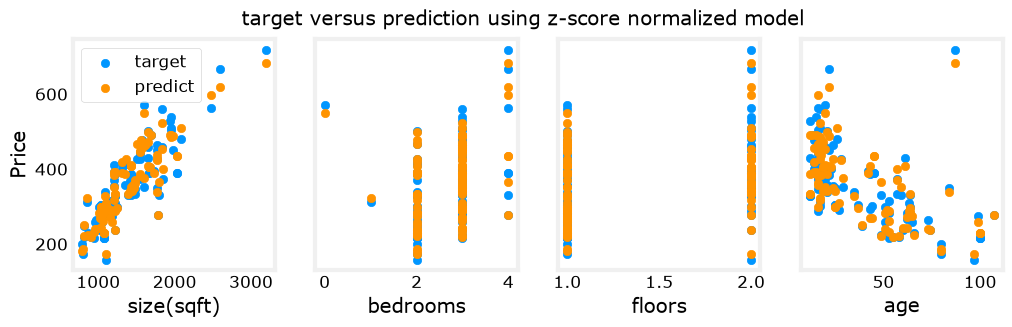

In [7]:
# plot predictions and targets vs original features    
fig,ax=plt.subplots(1,4,figsize=(12,3),sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train, label = 'target')
    ax[i].set_xlabel(X_features[i])
    ax[i].scatter(X_train[:,i],y_pred,color=dlc["dlorange"], label = 'predict')
ax[0].set_ylabel("Price"); ax[0].legend();
fig.suptitle("target versus prediction using z-score normalized model")
plt.show()

## 恭喜完成！
在本实验中，你：
- 使用了一个开源机器学习工具包 scikit-learn
- 用该工具包中的梯度下降和特征归一化实现了线性回归